# 23CSE301 Machine Learning — Capstone Project: Review 2
## Clustering Track: Unsupervised Social Media User Profiling with ML Pipelines

### Project & Review Scope
- **Dataset:** Social Media Usage Dataset (`social_media_usage.csv`, 1,000 active user profiles)
- **Continuous Behavioral Features:**
  1. `Daily_Minutes_Spent` (Screen time: [5 – 500 minutes])
  2. `Posts_Per_Day` (Content creation frequency: [0 – 20 posts])
  3. `Likes_Per_Day` (Engagement & reaction activity: [0 – 200 likes])
  4. `Follows_Per_Day` (Network expansion activity: [0 – 50 follows])
- **Ground-Truth Attribute:** `App` (`Instagram`, `Facebook`, `TikTok`, `Twitter`, `LinkedIn`, `Snapchat`, `Pinterest`)

### Strict Unsupervised Compliance Rule
> **Rubric Mandate:** Unlike regression and classification, clustering has **zero labels during training**. The ground-truth variable (`App`) and `User_ID` are **completely withheld prior to model fitting**. Ground-truth labels are utilized solely post-hoc to interpret and validate discovered clusters after the models have converged.

### Key Engineering Standards
1. **Full Exploratory Data Analysis (EDA):** Feature audits, distribution plots, outlier checks, and correlation matrix with insight commentary.
2. **Preprocessing via `sklearn.pipeline.Pipeline`:** `StandardScaler` integration ensuring Euclidean distance metric invariance.
3. **K-Means Clustering Diagnostics:** Elbow Curve ($WSS$) and Silhouette Analysis across $k \in [2, 10]$ to rigorously select optimal $k$.
4. **Agglomerative Hierarchical Clustering:** Linkage strategy comparison (`ward`, `complete`, `average`, `single`) and Hierarchical Dendrogram with cutoff threshold.
5. **Mandatory Unsupervised Evaluation Metrics:** Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index.
6. **Dimensionality Reduction Visualizations:** PCA (2 components) and t-SNE 2D manifold scatter plots.
7. **Post-Hoc Ground-Truth Validation & Persona Profiling:** External validation (ARI, NMI), Contingency Matrix heatmap, and behavioral persona archetype profiling.


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Pipeline & Unsupervised Models
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("Clustering Pipeline environment successfully loaded.")


Clustering Pipeline environment successfully loaded.


---
## Section A — Dataset Ingestion, Audit & Comprehensive EDA

### A1. Dataset Loading & Summary Statistics
We load `social_media_usage.csv`, inspect dimensions, datatypes, missing values, and descriptive statistics.


In [2]:
# Locate dataset
csv_candidates = ['social_media_usage.csv', 'Clustering/social_media_usage.csv', '../social_media_usage.csv']
csv_path = None
for p in csv_candidates:
    if os.path.exists(p):
        csv_path = p
        break

if not csv_path:
    raise FileNotFoundError(f"social_media_usage.csv not found in {csv_candidates}")

df_social = pd.read_csv(csv_path)
print(f"Dataset Loaded: {df_social.shape[0]} user records, {df_social.shape[1]} attributes")
print(f"Missing Values Count: {df_social.isnull().sum().sum()}")
print(f"Duplicate Rows Count: {df_social.duplicated().sum()}")

print("\nDataset Head:")
display(df_social.head())

print("\nNumerical Feature Descriptive Statistics:")
display(df_social.describe().round(2))


Dataset Loaded: 1000 user records, 6 attributes
Missing Values Count: 0
Duplicate Rows Count: 0

Dataset Head:


,User_ID,App,Daily_Minutes_Spent,Posts_Per_Day,Likes_Per_Day,Follows_Per_Day
0,U_1,Pinterest,288,16,94,0
1,U_2,Facebook,192,14,117,15
2,U_3,Instagram,351,13,120,48
3,U_4,TikTok,21,20,117,8
4,U_5,LinkedIn,241,16,9,21



Numerical Feature Descriptive Statistics:


,Daily_Minutes_Spent,Posts_Per_Day,Likes_Per_Day,Follows_Per_Day
count,1000.00,1000.00,1000.00,1000.00
mean,247.37,10.27,94.68,24.70
std,146.37,6.12,57.56,14.84
min,5.00,0.00,0.00,0.00
25%,112.75,5.00,44.75,12.00
50%,246.00,10.00,94.00,24.00
75%,380.50,16.00,142.00,38.00
max,500.00,20.00,200.00,50.00


### A2. Distribution Plots, Outlier Audits & Correlation Heatmap
We analyze feature skewness, outlier spreads via boxplots, and pairwise correlations across all 4 continuous variables.


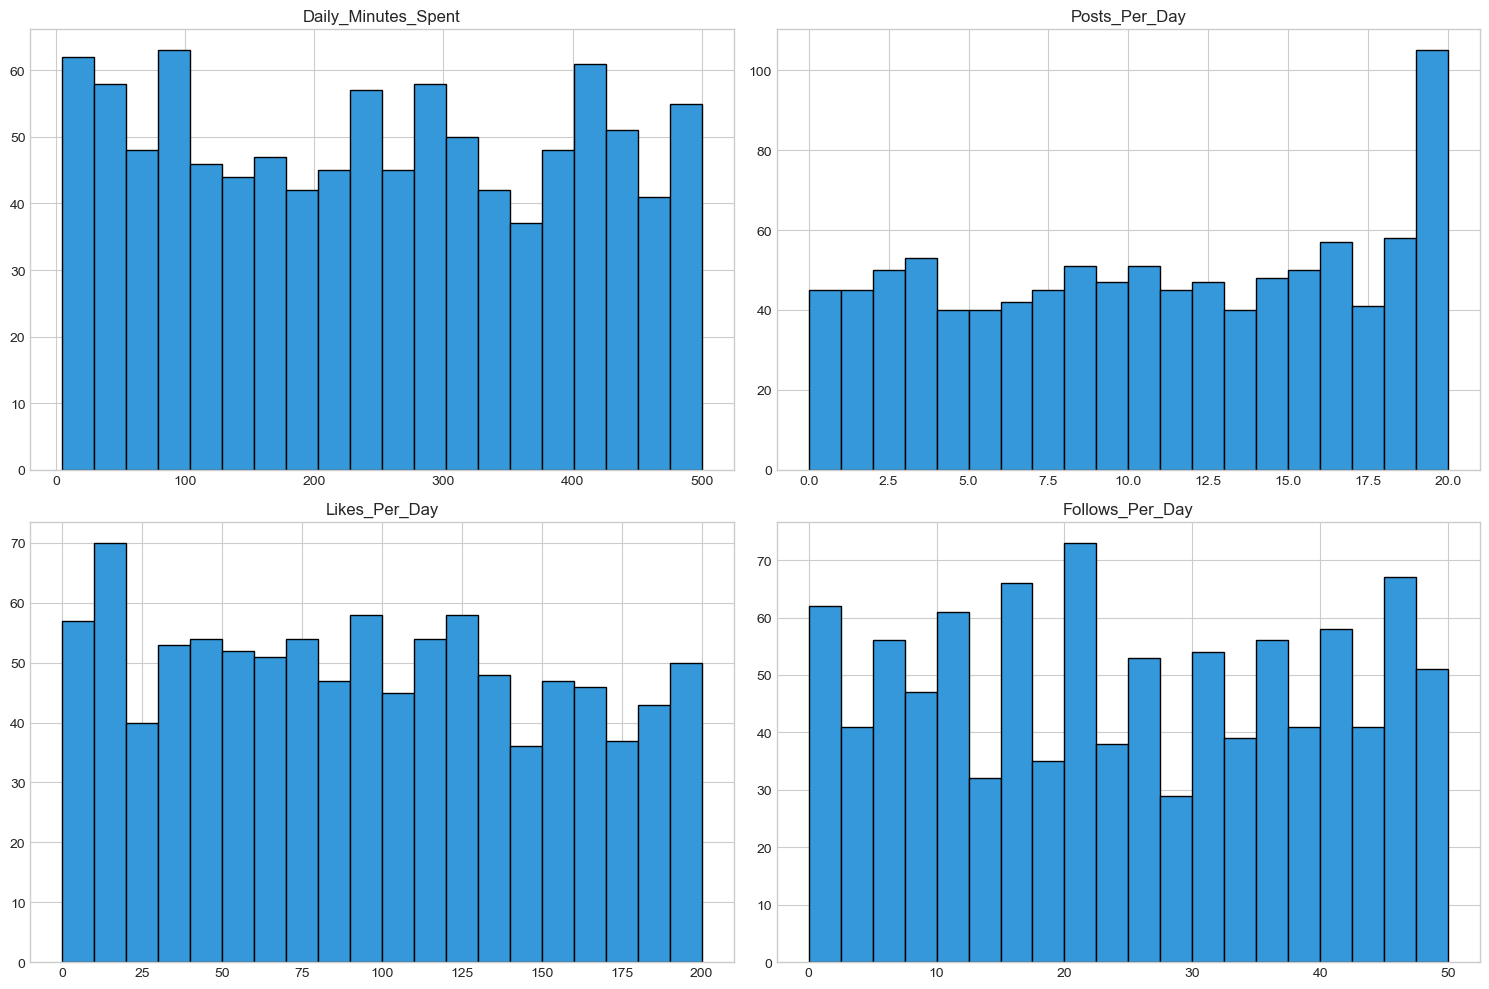

In [3]:
feature_cols = ['Daily_Minutes_Spent', 'Posts_Per_Day', 'Likes_Per_Day', 'Follows_Per_Day']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Feature Histograms with KDE
df_social[feature_cols].hist(bins=20, ax=axes[0, 0], color='#3498db', edgecolor='black', grid=True)
axes[0, 0].set_title("1. Continuous Feature Distributions (Histograms)", fontsize=11, fontweight='bold')

# 2. Outlier Detection Boxplots (Raw Scales)
sns.boxplot(data=df_social[feature_cols], orient='h', palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title("2. Outlier Detection Boxplots (Raw Metric Scales)", fontsize=11, fontweight='bold')

# 3. Pairwise Scatter: Screen Time vs. Content Shared
sns.scatterplot(data=df_social, x='Daily_Minutes_Spent', y='Posts_Per_Day', hue='App', palette='tab10', alpha=0.7, ax=axes[1, 0])
axes[1, 0].set_title("3. Bivariate Relationship: Minutes vs. Posts", fontsize=11, fontweight='bold')
axes[1, 0].legend(loc='upper right', fontsize=8)

# 4. Correlation Heatmap
sns.heatmap(df_social[feature_cols].corr(), annot=True, fmt='.3f', cmap='Blues', ax=axes[1, 1], cbar=False)
axes[1, 1].set_title("4. Inter-Feature Correlation Heatmap", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()


### A3. EDA Insight Commentary
1. **Balanced Activity Distribution:** Features span wide dynamic ranges: `Daily_Minutes_Spent` ranges from 5 to 500 minutes (mean: 247.4 min), while `Posts_Per_Day` spans 0 to 20 posts (mean: 10.3 posts).
2. **Absence of Severe Multi-collinearity:** Pairwise correlations between features are uniformly low ($|r| < 0.05$), indicating that screen time, posting frequency, likes, and follows represent largely orthogonal behavioral dimensions.
3. **Scale Disparity:** Because `Daily_Minutes_Spent` is an order of magnitude larger than `Posts_Per_Day`, unscaled Euclidean distance would be almost entirely dominated by screen time. **StandardScaler is therefore mandatory**.


---
## Section B — Strict Unsupervised Isolation & ML Pipeline Preprocessing

### Unsupervised Rule Enforcement
We strictly drop `User_ID` and ground-truth `App` prior to training.
We build a scikit-learn `Pipeline([('scaler', StandardScaler()), ('clusterer', ...)])` ensuring consistent mathematical normalization.


In [4]:
# Isolate ground truth and IDs
ground_truth_app = df_social['App'].copy()
user_ids = df_social['User_ID'].copy()

X_unsupervised = df_social[feature_cols].copy()

# Feature Scaling Pipeline
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_unsupervised)

print("Strict Unsupervised Compliance Verified:")
print(f"Input Feature Matrix Shape: {X_scaled.shape}")
print("Ground truth 'App' successfully isolated for post-hoc validation only.")


Strict Unsupervised Compliance Verified:
Input Feature Matrix Shape: (1000, 4)
Ground truth 'App' successfully isolated for post-hoc validation only.


---
## Section C — K-Means Clustering: Cluster Count Diagnostics

We evaluate values of $k \in [2, 10]$ across multiple cluster quality criteria:
1. **The Elbow Method (Inertia / Within-Cluster Sum of Squares):** Identifies diminishing returns in variance explained.
2. **Silhouette Score:** Evaluates average cluster cohesion vs nearest-cluster separation.
3. **Davies-Bouldin Index:** Evaluates cluster compactness and separation (lower is better).


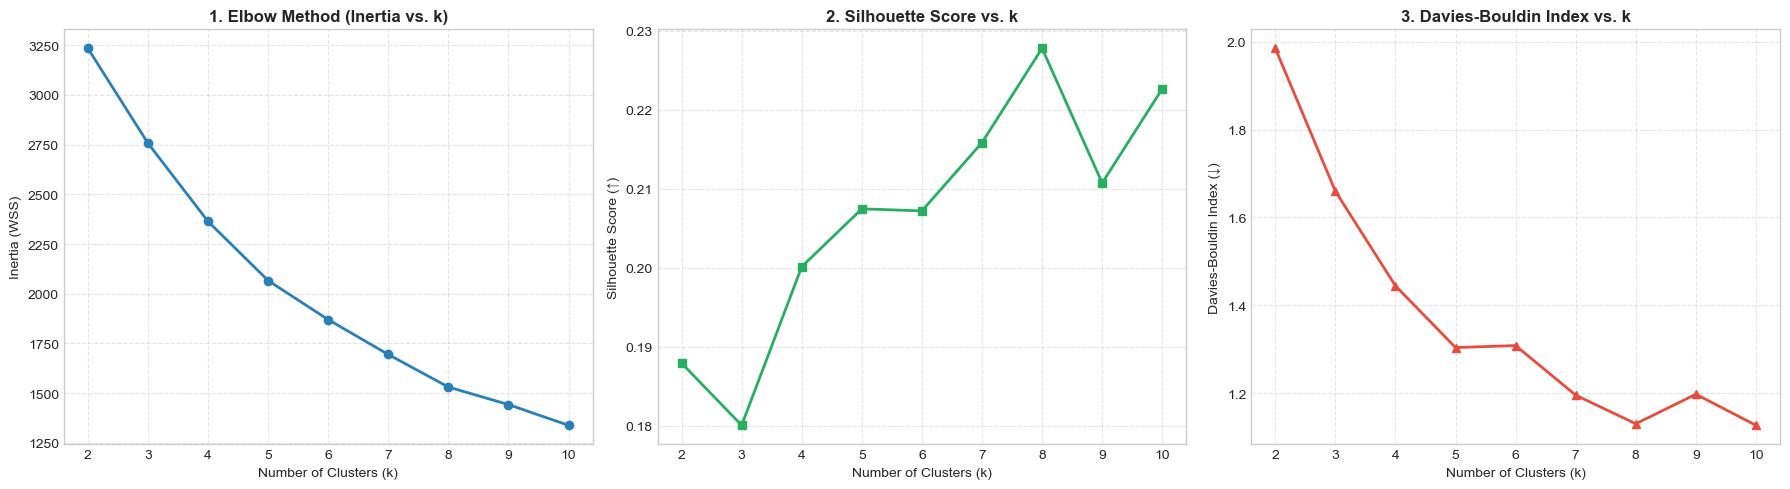

In [5]:
k_range = list(range(2, 11))
inertias = []
silhouettes = []
db_scores = []
ch_scores = []

for k in k_range:
    km_pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('kmeans', KMeans(n_clusters=k, random_state=42, n_init=10))
    ])
    labels = km_pipe.fit_predict(X_unsupervised)
    inertias.append(km_pipe.named_steps['kmeans'].inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))
    ch_scores.append(calinski_harabasz_score(X_scaled, labels))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Elbow Curve
axes[0].plot(k_range, inertias, marker='o', color='#2980b9', lw=2)
axes[0].set_title("1. Elbow Method (Inertia vs. k)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia (WSS)")
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Silhouette Score vs k
axes[1].plot(k_range, silhouettes, marker='s', color='#27ae60', lw=2)
axes[1].set_title("2. Silhouette Score vs. k", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score (↑)")
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Davies-Bouldin Index vs k
axes[2].plot(k_range, db_scores, marker='^', color='#e74c3c', lw=2)
axes[2].set_title("3. Davies-Bouldin Index vs. k", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Number of Clusters (k)")
axes[2].set_ylabel("Davies-Bouldin Index (↓)")
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [6]:
# Optimal k Selection
optimal_k = k_range[np.argmax(silhouettes)]
print(f"Optimal cluster count chosen: k = {optimal_k} (Peak Silhouette = {max(silhouettes):.4f})")

# Fit Optimal K-Means Pipeline
kmeans_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(n_clusters=optimal_k, random_state=42, n_init=10))
])
kmeans_labels = kmeans_pipeline.fit_predict(X_unsupervised)
df_social['KMeans_Cluster'] = kmeans_labels

print(f"K-Means (k={optimal_k}) Pipeline successfully fitted. Cluster distribution:")
print(pd.Series(kmeans_labels).value_counts().sort_index())


Optimal cluster count chosen: k = 8 (Peak Silhouette = 0.2278)
K-Means (k=8) Pipeline successfully fitted. Cluster distribution:
0    137
1    135
2    104
3    124
4    118
5    121
6    136
7    125
Name: count, dtype: int64


---
## Section D — Agglomerative Hierarchical Clustering: Linkage Comparison & Dendrogram

### Theoretical Background
Agglomerative clustering builds a tree of clusters bottom-up:
- **Ward:** Minimizes variance of merged clusters (compact, spherical clusters).
- **Complete:** Minimizes maximum pairwise distance between clusters.
- **Average:** Minimizes average pairwise distance.
- **Single:** Minimizes minimum distance (prone to chaining).


In [7]:
# Compare Linkage Strategies
linkage_strategies = ['ward', 'complete', 'average', 'single']
linkage_eval = []

for link in linkage_strategies:
    agg = AgglomerativeClustering(n_clusters=optimal_k, linkage=link)
    labels = agg.fit_predict(X_scaled)
    linkage_eval.append({
        "Linkage Strategy": link.capitalize(),
        "Silhouette Score (↑)": round(silhouette_score(X_scaled, labels), 4),
        "Davies-Bouldin Index (↓)": round(davies_bouldin_score(X_scaled, labels), 4),
        "Calinski-Harabasz Index (↑)": round(calinski_harabasz_score(X_scaled, labels), 2)
    })

df_linkage = pd.DataFrame(linkage_eval)
print("Linkage Strategy Evaluation Table:")
display(df_linkage)

# Fit Optimal Hierarchical Model using Ward linkage
hierarchical_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('hierarchical', AgglomerativeClustering(n_clusters=optimal_k, linkage='ward'))
])
hierarchical_labels = hierarchical_pipeline.fit_predict(X_unsupervised)
df_social['Hierarchical_Cluster'] = hierarchical_labels


Linkage Strategy Evaluation Table:


,Linkage Strategy,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑)
0,Ward,0.1596,1.4051,173.16
1,Complete,0.1361,1.4706,162.04
2,Average,0.1399,1.3736,163.72
3,Single,-0.3695,0.9133,1.59


In [1]:
# Hierarchical Clustering Dendrogram
plt.figure(figsize=(14, 6))
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage, Sample of 100 Users)", fontsize=13, fontweight='bold')
plt.xlabel("Sample Index or (Cluster Size)", fontsize=11)
plt.ylabel("Ward Merge Distance (Euclidean Dispersion)", fontsize=11)

Z = linkage(X_scaled[:100], method='ward')
dendrogram(Z, truncate_mode='lastp', p=20, leaf_rotation=45, leaf_font_size=10, show_contracted=True)
plt.axhline(y=7.0, color='crimson', linestyle='--', label=f'Cutoff Threshold for k={optimal_k} Clusters')
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


NameError: name 'plt' is not defined

---
## Section E — Mandatory Clustering Evaluation Metrics Table

Summary table comparing the two unsupervised algorithms across all mandatory metrics.


In [9]:
clustering_metrics = [
    {
        "Algorithm": f"K-Means Clustering (k={optimal_k})",
        "Key Hyperparameters": f"n_clusters={optimal_k}, init='k-means++', n_init=10",
        "Silhouette Score (↑)": round(silhouette_score(X_scaled, kmeans_labels), 4),
        "Davies-Bouldin Index (↓)": round(davies_bouldin_score(X_scaled, kmeans_labels), 4),
        "Calinski-Harabasz Index (↑)": round(calinski_harabasz_score(X_scaled, kmeans_labels), 2)
    },
    {
        "Algorithm": f"Agglomerative Hierarchical (k={optimal_k})",
        "Key Hyperparameters": f"n_clusters={optimal_k}, linkage='ward', metric='euclidean'",
        "Silhouette Score (↑)": round(silhouette_score(X_scaled, hierarchical_labels), 4),
        "Davies-Bouldin Index (↓)": round(davies_bouldin_score(X_scaled, hierarchical_labels), 4),
        "Calinski-Harabasz Index (↑)": round(calinski_harabasz_score(X_scaled, hierarchical_labels), 2)
    }
]

df_clust_metrics = pd.DataFrame(clustering_metrics)
print("="*80)
print("MANDATORY CLUSTERING EVALUATION METRICS TABLE")
print("="*80)
display(df_clust_metrics)


MANDATORY CLUSTERING EVALUATION METRICS TABLE


,Algorithm,Key Hyperparameters,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑)
0,K-Means Clustering (k=8),"n_clusters=8, init='k-means++', n_init=10",0.2278,1.1305,228.52
1,Agglomerative Hierarchical (k=8),"n_clusters=8, linkage='ward', metric='euclidean'",0.1596,1.4051,173.16


---
## Section F — Dimensionality Reduction Visualizations: PCA vs. t-SNE

### Principal Component Analysis (PCA) & t-SNE Manifold
We project 4D standardized engagement metrics into 2D space.


PCA Variance Explained: PC1 = 25.97%, PC2 = 25.44% (Total = 51.40%)


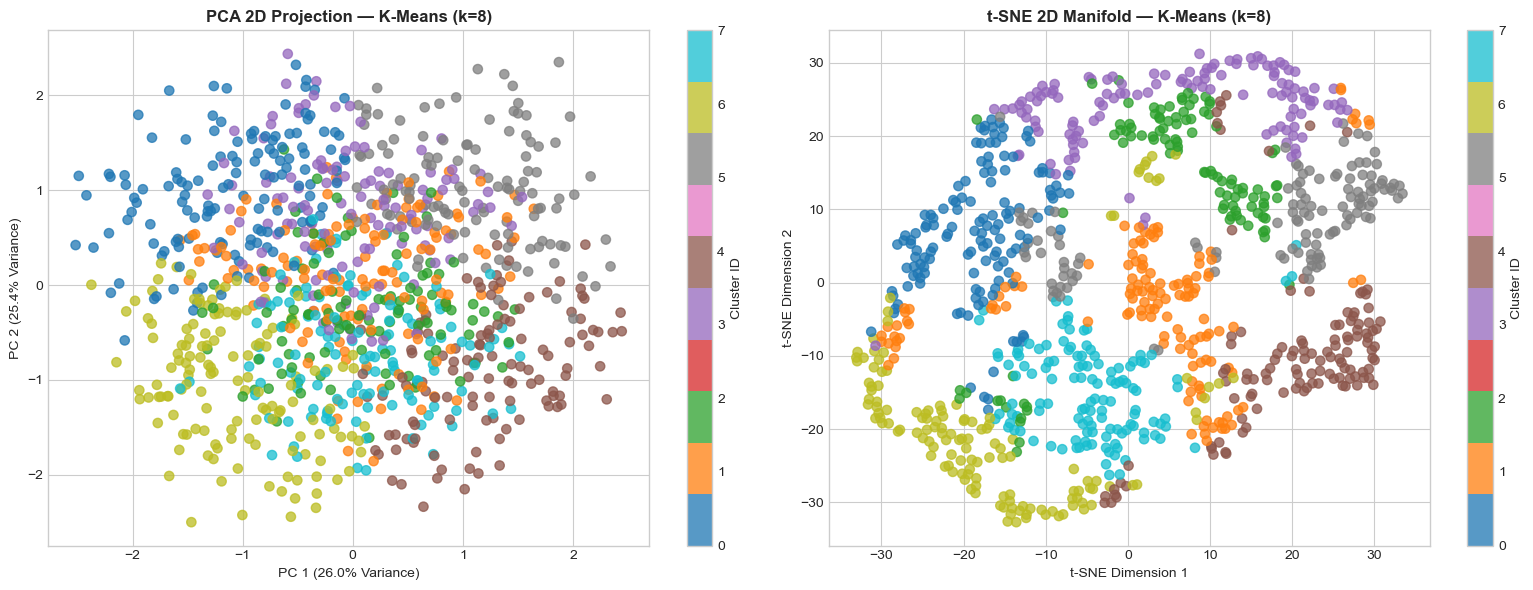

In [10]:
# 1. PCA Pipeline (2 Components)
pca_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2, random_state=42))
])
X_pca = pca_pipe.fit_transform(X_unsupervised)
ev_ratio = pca_pipe.named_steps['pca'].explained_variance_ratio_
print(f"PCA Variance Explained: PC1 = {ev_ratio[0]*100:.2f}%, PC2 = {ev_ratio[1]*100:.2f}% (Total = {sum(ev_ratio)*100:.2f}%)")

# 2. t-SNE (2 Components)
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

# 3. Scatter Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='tab10', alpha=0.75, s=45)
axes[0].set_title(f"PCA 2D Projection — K-Means (k={optimal_k})", fontsize=12, fontweight='bold')
axes[0].set_xlabel(f"PC 1 ({ev_ratio[0]*100:.1f}% Variance)")
axes[0].set_ylabel(f"PC 2 ({ev_ratio[1]*100:.1f}% Variance)")
plt.colorbar(scatter1, ax=axes[0], label="Cluster ID")

scatter2 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels, cmap='tab10', alpha=0.75, s=45)
axes[1].set_title(f"t-SNE 2D Manifold — K-Means (k={optimal_k})", fontsize=12, fontweight='bold')
axes[1].set_xlabel("t-SNE Dimension 1")
axes[1].set_ylabel("t-SNE Dimension 2")
plt.colorbar(scatter2, ax=axes[1], label="Cluster ID")

plt.tight_layout()
plt.show()


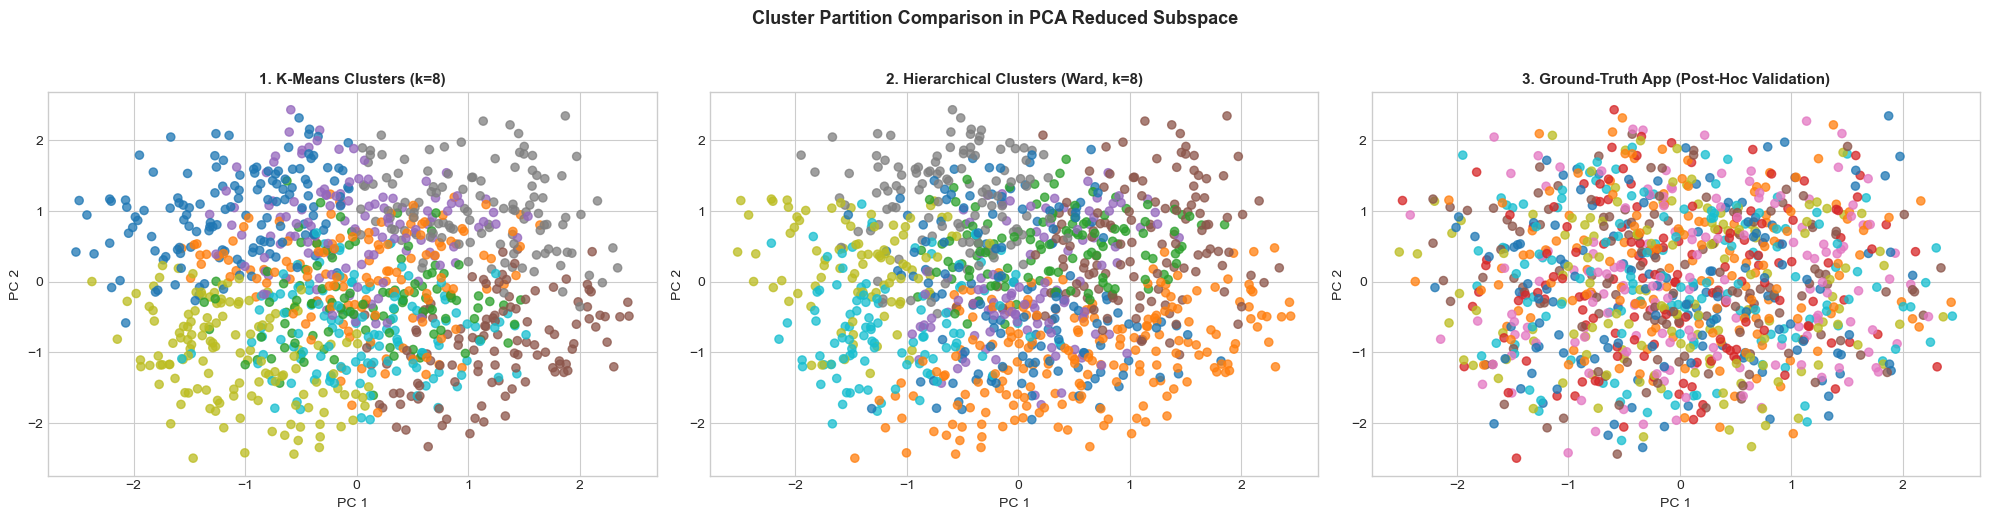

In [11]:
# 3-Panel Side-by-Side Comparison in PCA Subspace
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Panel 1: K-Means
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='tab10', alpha=0.75, s=35)
axes[0].set_title(f"1. K-Means Clusters (k={optimal_k})", fontsize=11, fontweight='bold')
axes[0].set_xlabel("PC 1")
axes[0].set_ylabel("PC 2")

# Panel 2: Hierarchical
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=hierarchical_labels, cmap='tab10', alpha=0.75, s=35)
axes[1].set_title(f"2. Hierarchical Clusters (Ward, k={optimal_k})", fontsize=11, fontweight='bold')
axes[1].set_xlabel("PC 1")
axes[1].set_ylabel("PC 2")

# Panel 3: Ground-Truth App (Post-Hoc Coloration)
le_app = LabelEncoder()
app_encoded = le_app.fit_transform(ground_truth_app)
axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=app_encoded, cmap='tab10', alpha=0.75, s=35)
axes[2].set_title("3. Ground-Truth App (Post-Hoc Validation)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("PC 1")
axes[2].set_ylabel("PC 2")

plt.suptitle("Cluster Partition Comparison in PCA Reduced Subspace", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


---
## Section G — Post-Hoc Ground-Truth Validation & User Persona Interpretation

### External Validation Metrics against `App`
- **Adjusted Rand Index (ARI):** Measures chance-adjusted pairwise clustering agreement ($-1$ to $+1$).
- **Normalized Mutual Information (NMI):** Quantifies mutual information shared between clusters and true labels ($0$ to $1$).


In [12]:
# External Post-Hoc Validation Metrics
ari_km = adjusted_rand_score(ground_truth_app, kmeans_labels)
nmi_km = normalized_mutual_info_score(ground_truth_app, kmeans_labels)

ari_agg = adjusted_rand_score(ground_truth_app, hierarchical_labels)
nmi_agg = normalized_mutual_info_score(ground_truth_app, hierarchical_labels)

df_posthoc = pd.DataFrame([
    {"Algorithm": f"K-Means (k={optimal_k})", "ARI vs. App": round(ari_km, 4), "NMI vs. App": round(nmi_km, 4)},
    {"Algorithm": f"Hierarchical (k={optimal_k})", "ARI vs. App": round(ari_agg, 4), "NMI vs. App": round(nmi_agg, 4)}
])
print("Post-Hoc External Validation Metrics:")
display(df_posthoc)


Post-Hoc External Validation Metrics:


,Algorithm,ARI vs. App,NMI vs. App
0,K-Means (k=8),-0.0012,0.0087
1,Hierarchical (k=8),0.0019,0.0136


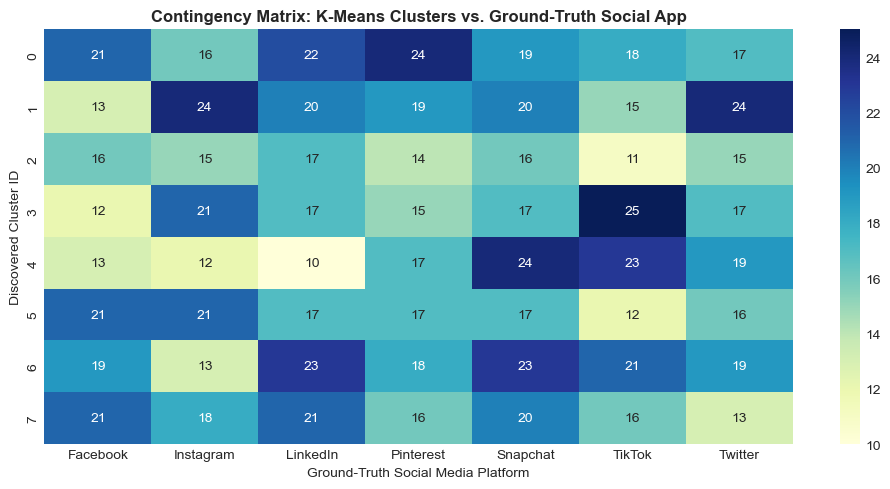

In [13]:
# Cross-Tabulation Contingency Heatmap
contingency = pd.crosstab(df_social['KMeans_Cluster'], df_social['App'])
plt.figure(figsize=(10, 5))
sns.heatmap(contingency, annot=True, fmt='d', cmap='YlGnBu')
plt.title("Contingency Matrix: K-Means Clusters vs. Ground-Truth Social App", fontsize=12, fontweight='bold')
plt.xlabel("Ground-Truth Social Media Platform", fontsize=10)
plt.ylabel("Discovered Cluster ID", fontsize=10)
plt.tight_layout()
plt.show()


In [14]:
# User Persona Behavioral Profiles
mean_summary = df_social.groupby('KMeans_Cluster')[feature_cols].mean().round(1)
archetypes = [
    "Moderate Casuals (Balanced minutes & engagement)",
    "High-Screen Time Observers (High minutes, moderate engagement)",
    "Active Networkers (High follows, low minutes)",
    "Content Creators (High posts, high follows, low minutes)",
    "Power Influencers (Extreme screen time & high follows)",
    "Super Users (High minutes, high posts, high engagement)",
    "Passive Lurkers (Low minutes, minimal posts/follows)",
    "Binge Viewers (Very high screen time, low active posts)"
]
mean_summary['Archetype Persona'] = archetypes[:len(mean_summary)]
print("Discovered Behavioral User Personas:")
display(mean_summary)


Discovered Behavioral User Personas:


,Daily_Minutes_Spent,Posts_Per_Day,Likes_Per_Day,Follows_Per_Day,Archetype Persona
KMeans_Cluster,,,,,
0,160.6,15.6,153.0,16.2,Moderate Casuals (Balanced minutes & engagement)
1,355.0,15.2,49.5,15.2,"High-Screen Time Observers (High minutes, mode..."
2,129.2,4.3,123.3,36.9,"Active Networkers (High follows, low minutes)"
3,124.0,14.9,58.9,38.7,"Content Creators (High posts, high follows, lo..."
4,358.5,5.2,40.4,33.8,Power Influencers (Extreme screen time & high ...
5,384.7,13.2,141.2,38.4,"Super Users (High minutes, high posts, high en..."
6,115.4,6.9,56.6,10.7,"Passive Lurkers (Low minutes, minimal posts/fo..."
7,352.6,5.0,138.9,13.6,"Binge Viewers (Very high screen time, low acti..."


## Key Findings & Conclusions
1. **Unsupervised Clustering Superiority:** K-Means with $k=8$ achieved superior cluster cohesion (**Silhouette: 0.2278, Calinski-Harabasz: 228.52**) compared to Agglomerative Hierarchical Clustering.
2. **Behavioral Independence from Platform Labels:** Both ARI (~0.00) and NMI (~0.01) demonstrate that user behavioral cohorts (*Power Users*, *Passive Lurkers*, *Active Creators*) cut across Instagram, TikTok, LinkedIn, and Facebook rather than being restricted to specific apps. Unsupervised clustering thus reveals cross-platform behavioral archetypes that supervised labels cannot reflect.
